In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Environment setup successful!")

Python version: 3.10.22 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:15:38) [MSC v.1942 64 bit (AMD64)]
Python executable: c:\Users\sarka\anaconda3\envs\analytics\python.exe
Environment setup successful!


In [2]:
import pandas as pd
from pathlib import Path

# Locate the project and data folders
project_dir = Path.cwd().parent
data_dir = project_dir / "data"

# Find CSV files
csv_files = list(data_dir.glob("*.csv"))

print("Data folder:", data_dir)
print("CSV files found:", [file.name for file in csv_files])

Data folder: c:\Users\sarka\Documents\apexplanet-data-analytics\data
CSV files found: ['Amazon Sale Report.csv', 'Amazon_Sale_Report_Cleaned.csv']


In [3]:
import pandas as pd
from pathlib import Path

# Locate the project directory
project_dir = Path.cwd().parent
data_dir = project_dir / "data"

# Find the CSV file
csv_files = list(data_dir.glob("*.csv"))

if not csv_files:
    print("No CSV file found. Please check the data folder.")
else:
    file_path = csv_files[0]
    print("Dataset:", file_path.name)

    # Load the dataset
    df = pd.read_csv(file_path, low_memory=False)

    print("\nDataset loaded successfully!")
    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])

    display(df.head())

Dataset: Amazon Sale Report.csv

Dataset loaded successfully!
Number of rows: 128975
Number of columns: 24


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape: (128975, 24)

Column names:
['index', 'Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ', 'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN', 'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids', 'B2B', 'fulfilled-by', 'Unnamed: 22']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  int64  
 1   Order ID            128975 non-null  object 
 2   Date                128975 non-null  object 
 3   Status              128975 non-null  object 
 4   Fulfilment          128975 non-null  object 
 5   Sales Channel       128975 non-null  object 
 6   ship-service-level  128975 non-null  object 
 7   Style               128975 non-null  object 
 8   SKU  

In [5]:
# 1. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2. Inspect missing values
print("\nMissing values:")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

# 3. Inspect suspicious columns
print("\nUnnamed column values:")
print(df["Unnamed: 22"].value_counts(dropna=False).head(10))

# 4. Inspect dates
print("\nSample dates:")
print(df["Date"].head(10))

# 5. Inspect sales amounts and quantities
print("\nSales amount summary:")
print(df["Amount"].describe())

print("\nQuantity summary:")
print(df["Qty"].describe())

Duplicate rows: 0

Missing values:
fulfilled-by        89698
promotion-ids       49153
Unnamed: 22         49050
currency             7795
Amount               7795
Courier Status       6872
ship-postal-code       33
ship-state             33
ship-city              33
ship-country           33
dtype: int64

Unnamed column values:
Unnamed: 22
False    79925
NaN      49050
Name: count, dtype: int64

Sample dates:
0    04-30-22
1    04-30-22
2    04-30-22
3    04-30-22
4    04-30-22
5    04-30-22
6    04-30-22
7    04-30-22
8    04-30-22
9    04-30-22
Name: Date, dtype: object

Sales amount summary:
count    121180.000000
mean        648.561465
std         281.211687
min           0.000000
25%         449.000000
50%         605.000000
75%         788.000000
max        5584.000000
Name: Amount, dtype: float64

Quantity summary:
count    128975.000000
mean          0.904431
std           0.313354
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max

In [6]:
# Create a working copy so the original DataFrame remains unchanged
df_clean = df.copy()

# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Cleaned column names:")
print(df_clean.columns.tolist())

Cleaned column names:
['index', 'order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'promotion_ids', 'b2b', 'fulfilled_by', 'unnamed_22']


In [7]:
# Inspect orders with missing amounts
missing_amount = df_clean[df_clean["amount"].isna()]

print("Rows with missing amounts:", len(missing_amount))

print("\nOrder status:")
print(missing_amount["status"].value_counts(dropna=False))

print("\nQuantity summary:")
print(missing_amount["qty"].describe())

print("\nSample rows:")
display(
    missing_amount[
        ["order_id", "date", "status", "category", "qty", "currency", "amount"]
    ].head(10)
)

Rows with missing amounts: 7795

Order status:
status
Cancelled                       7566
Shipped                          208
Shipped - Delivered to Buyer       8
Shipping                           8
Shipped - Returned to Seller       3
Pending                            2
Name: count, dtype: int64

Quantity summary:
count    7795.000000
mean        0.021424
std         0.283726
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        15.000000
Name: qty, dtype: float64

Sample rows:


,order_id,date,status,category,qty,currency,amount
8,407-5443024-5233168,04-30-22,Cancelled,Set,0,NaN,NaN
29,404-5933402-8801952,04-30-22,Cancelled,kurta,0,NaN,NaN
65,171-4137548-0481151,04-30-22,Cancelled,kurta,0,NaN,NaN
84,403-9950518-0349133,04-30-22,Cancelled,kurta,0,NaN,NaN
95,405-9112089-3379536,04-30-22,Cancelled,kurta,0,NaN,NaN
101,402-7841951-1872363,04-30-22,Cancelled,Set,0,NaN,NaN
132,171-0293372-4913973,04-30-22,Cancelled,Set,0,NaN,NaN
139,403-6442534-2769112,04-30-22,Cancelled,Top,0,NaN,NaN
155,402-8078642-8565124,04-30-22,Cancelled,kurta,0,NaN,NaN
165,406-0218328-1773963,04-30-22,Cancelled,kurta,0,NaN,NaN


In [8]:
# Separate cancelled and non-cancelled rows with missing amounts
missing_amount = df_clean[df_clean["amount"].isna()]

non_cancelled_missing = missing_amount[
    missing_amount["status"] != "Cancelled"
]

print("Missing amounts in cancelled orders:",
      (missing_amount["status"] == "Cancelled").sum())

print("\nMissing amounts in other statuses:",
      len(non_cancelled_missing))

print("\nOther statuses:")
print(non_cancelled_missing["status"].value_counts())

print("\nSample of non-cancelled orders with missing amounts:")
display(
    non_cancelled_missing[
        ["order_id", "date", "status", "fulfilment",
         "category", "qty", "currency", "amount"]
    ].head(20)
)

Missing amounts in cancelled orders: 7566

Missing amounts in other statuses: 229

Other statuses:
status
Shipped                         208
Shipped - Delivered to Buyer      8
Shipping                          8
Shipped - Returned to Seller      3
Pending                           2
Name: count, dtype: int64

Sample of non-cancelled orders with missing amounts:


,order_id,date,status,fulfilment,category,qty,currency,amount
937,S02-5278980-4327051,04-30-22,Shipped,Amazon,Blouse,15,NaN,NaN
1057,S02-9107114-0460608,04-30-22,Shipped,Amazon,Set,2,NaN,NaN
1615,405-7790745-1369118,04-29-22,Shipped,Amazon,kurta,0,NaN,NaN
1989,171-9673855-2321133,04-29-22,Shipped,Amazon,Set,0,NaN,NaN
2424,404-7478762-7926753,04-29-22,Shipped,Amazon,Set,0,NaN,NaN
2819,404-0814480-8157169,04-29-22,Shipped,Amazon,kurta,0,NaN,NaN
3631,S02-1006261-5356758,04-28-22,Shipped,Amazon,kurta,9,NaN,NaN
3632,S02-3681731-6111841,04-28-22,Shipped,Amazon,kurta,1,NaN,NaN
3634,S02-1926028-4838217,04-28-22,Shipped,Amazon,kurta,1,NaN,NaN
3636,S02-6828927-1180856,04-28-22,Shipped,Amazon,kurta,13,NaN,NaN


In [9]:
# Check whether the 229 orders have missing quantities or other fields
columns_to_check = [
    "order_id",
    "date",
    "status",
    "category",
    "qty",
    "currency",
    "amount"
]

display(
    non_cancelled_missing[columns_to_check]
    .head(15)
    .to_string(index=False)
)

print("\nMissing values in these 229 orders:")
display(
    non_cancelled_missing[columns_to_check]
    .isna()
    .sum()
)

'           order_id     date  status category  qty currency  amount\nS02-5278980-4327051 04-30-22 Shipped   Blouse   15      NaN     NaN\nS02-9107114-0460608 04-30-22 Shipped      Set    2      NaN     NaN\n405-7790745-1369118 04-29-22 Shipped    kurta    0      NaN     NaN\n171-9673855-2321133 04-29-22 Shipped      Set    0      NaN     NaN\n404-7478762-7926753 04-29-22 Shipped      Set    0      NaN     NaN\n404-0814480-8157169 04-29-22 Shipped    kurta    0      NaN     NaN\nS02-1006261-5356758 04-28-22 Shipped    kurta    9      NaN     NaN\nS02-3681731-6111841 04-28-22 Shipped    kurta    1      NaN     NaN\nS02-1926028-4838217 04-28-22 Shipped    kurta    1      NaN     NaN\nS02-6828927-1180856 04-28-22 Shipped    kurta   13      NaN     NaN\nS02-3409426-0744131 04-28-22 Shipped   Blouse    2      NaN     NaN\nS02-8357726-8633940 04-28-22 Shipped      Set    1      NaN     NaN\nS02-6358630-3384547 04-28-22 Shipped   Blouse    1      NaN     NaN\nS02-8920429-3367507 04-28-22 Ship


Missing values in these 229 orders:


order_id      0
date          0
status        0
category      0
qty           0
currency    229
amount      229
dtype: int64

In [10]:
print("Values in unnamed_22:")
print(df_clean["unnamed_22"].value_counts(dropna=False))

print("\nUnique values:")
print(df_clean["unnamed_22"].unique())

Values in unnamed_22:
unnamed_22
False    79925
NaN      49050
Name: count, dtype: int64

Unique values:
[nan False]


In [11]:
# Remove the unnecessary column
df_clean = df_clean.drop(columns=["unnamed_22"])

print("Column removed successfully!")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nRemaining columns:")
print(df_clean.columns.tolist())

Column removed successfully!
Rows: 128975
Columns: 23

Remaining columns:
['index', 'order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'promotion_ids', 'b2b', 'fulfilled_by']


In [12]:
# Convert dates safely
df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    format="mixed",
    errors="coerce"
)

print("Date conversion completed!")
print("Data type:", df_clean["date"].dtype)
print("Earliest date:", df_clean["date"].min())
print("Latest date:", df_clean["date"].max())
print("Missing or invalid dates:", df_clean["date"].isna().sum())

display(df_clean[["order_id", "date"]].head(10))



Date conversion completed!
Data type: datetime64[ns]
Earliest date: 2022-03-31 00:00:00
Latest date: 2022-06-29 00:00:00
Missing or invalid dates: 0


,order_id,date
0,405-8078784-5731545,2022-04-30
1,171-9198151-1101146,2022-04-30
2,404-0687676-7273146,2022-04-30
3,403-9615377-8133951,2022-04-30
4,407-1069790-7240320,2022-04-30
5,404-1490984-4578765,2022-04-30
6,408-5748499-6859555,2022-04-30
7,406-7807733-3785945,2022-04-30
8,407-5443024-5233168,2022-04-30
9,402-4393761-0311520,2022-04-30


In [13]:

# Check missing values after the previous cleaning steps
missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isna().sum(),
    "Missing Percentage": (
        df_clean.isna().sum() / len(df_clean) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Count", ascending=False)

display(missing_summary)



,Missing Count,Missing Percentage
fulfilled_by,89698,69.55
promotion_ids,49153,38.11
currency,7795,6.04
amount,7795,6.04
courier_status,6872,5.33
ship_state,33,0.03
ship_city,33,0.03
ship_country,33,0.03
ship_postal_code,33,0.03


In [14]:

# Investigate missing fulfilled_by values
print("Fulfilment methods:")
display(df_clean["fulfilment"].value_counts(dropna=False))

print("\nFulfilled_by values by fulfilment method:")
display(
    pd.crosstab(
        df_clean["fulfilment"],
        df_clean["fulfilled_by"],
        dropna=False
    )
)



Fulfilment methods:


fulfilment
Amazon      89698
Merchant    39277
Name: count, dtype: int64


Fulfilled_by values by fulfilment method:


fulfilled_by,Easy Ship,NaN
fulfilment,,
Amazon,0,89698
Merchant,39277,0


In [15]:

# Fill missing fulfilled_by values with an explicit label
df_clean["fulfilled_by"] = df_clean["fulfilled_by"].fillna(
    "Not Applicable"
)

# Verify the result
print("Missing values remaining:", df_clean["fulfilled_by"].isna().sum())

print("\nUpdated fulfilled_by counts:")
display(df_clean["fulfilled_by"].value_counts())



Missing values remaining: 0

Updated fulfilled_by counts:


fulfilled_by
Not Applicable    89698
Easy Ship         39277
Name: count, dtype: int64

In [16]:
 id="prom1"
# Inspect promotion IDs
print("Number of unique promotion IDs:")
print(df_clean["promotion_ids"].nunique())

print("\nMost common promotion IDs:")
display(df_clean["promotion_ids"].value_counts().head(10))

print("\nSample promotion IDs, including missing values:")
display(df_clean["promotion_ids"].head(20))



Number of unique promotion IDs:
5787

Most common promotion IDs:


promotion_ids
IN Core Free Shipping 2015/04/08 23-48-5-108                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              


Sample promotion IDs, including missing values:


0                                                   NaN
1     Amazon PLCC Free-Financing Universal Merchant ...
2          IN Core Free Shipping 2015/04/08 23-48-5-108
3                                                   NaN
4                                                   NaN
5          IN Core Free Shipping 2015/04/08 23-48-5-108
6          IN Core Free Shipping 2015/04/08 23-48-5-108
7     Amazon PLCC Free-Financing Universal Merchant ...
8          IN Core Free Shipping 2015/04/08 23-48-5-108
9                                                   NaN
10                                                  NaN
11                                                  NaN
12    Amazon PLCC Free-Financing Universal Merchant ...
13                                                  NaN
14    Amazon PLCC Free-Financing Universal Merchant ...
15    Amazon PLCC Free-Financing Universal Merchant ...
16         IN Core Free Shipping 2015/04/08 23-48-5-108
17                                              

In [17]:

# Count missing and non-missing promotion IDs
missing_promotions = df_clean["promotion_ids"].isna().sum()
available_promotions = df_clean["promotion_ids"].notna().sum()

print("Missing promotion IDs:", missing_promotions)
print("Recorded promotion IDs:", available_promotions)

print(
    "\nUnique recorded promotion entries:",
    df_clean["promotion_ids"].nunique()
)

print("\nTop 10 promotion entries:")
display(
    df_clean["promotion_ids"]
    .value_counts()
    .head(10)
)



Missing promotion IDs: 49153
Recorded promotion IDs: 79822

Unique recorded promotion entries: 5787

Top 10 promotion entries:


promotion_ids
IN Core Free Shipping 2015/04/08 23-48-5-108                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [18]:

# Preserve missing promotion information with a clear label
df_clean["promotion_ids"] = df_clean["promotion_ids"].fillna(
    "No Promotion Recorded"
)

# Verify the result
print(
    "Missing promotion IDs remaining:",
    df_clean["promotion_ids"].isna().sum()
)

print("\nUpdated promotion counts:")
display(
    df_clean["promotion_ids"]
    .value_counts()
    .head(10)
)



Missing promotion IDs remaining: 0

Updated promotion counts:


promotion_ids
No Promotion Recorded                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [19]:

# Investigate missing shipping details
location_columns = [
    "ship_city",
    "ship_state",
    "ship_country",
    "ship_postal_code"
]

# Count rows with missing values in all four columns
all_location_missing = df_clean[location_columns].isna().all(axis=1)

print("Rows missing all four shipping details:",
      all_location_missing.sum())

print("\nMissing values by shipping column:")
print(df_clean[location_columns].isna().sum())

print("\nSample affected records:")
display(
    df_clean.loc[
        all_location_missing,
        ["order_id", "status"] + location_columns
    ].head(10)
)



Rows missing all four shipping details: 33

Missing values by shipping column:
ship_city           33
ship_state          33
ship_country        33
ship_postal_code    33
dtype: int64

Sample affected records:


,order_id,status,ship_city,ship_state,ship_country,ship_postal_code
1871,404-0566904-4825137,Shipped,NaN,NaN,NaN,NaN
1872,404-0566904-4825137,Shipped,NaN,NaN,NaN,NaN
8752,406-4003386-8768363,Shipped,NaN,NaN,NaN,NaN
11215,402-0107720-7057168,Shipped,NaN,NaN,NaN,NaN
13252,407-4532637-8415521,Cancelled,NaN,NaN,NaN,NaN
15688,404-9229894-8608305,Shipped,NaN,NaN,NaN,NaN
16787,402-4919636-4333150,Shipped - Delivered to Buyer,NaN,NaN,NaN,NaN
18351,405-4927647-8064368,Shipped,NaN,NaN,NaN,NaN
22930,402-8628677-0457954,Shipped - Returned to Seller,NaN,NaN,NaN,NaN
24986,406-4079063-8291520,Cancelled,NaN,NaN,NaN,NaN


In [20]:
# Investigate missing courier status
print("Missing courier status:", df_clean["courier_status"].isna().sum())

print("\nOrder status for rows with missing courier status:")
print(
    df_clean.loc[
        df_clean["courier_status"].isna(),
        "status"
    ].value_counts(dropna=False)
)

print("\nSample affected records:")
display(
    df_clean.loc[
        df_clean["courier_status"].isna(),
        ["order_id", "status", "fulfilment", "courier_status"]
    ].head(10)
)

Missing courier status: 6872

Order status for rows with missing courier status:
status
Cancelled                       6861
Shipped - Delivered to Buyer       8
Shipped - Returned to Seller       3
Name: count, dtype: int64

Sample affected records:


,order_id,status,fulfilment,courier_status
0,405-8078784-5731545,Cancelled,Merchant,NaN
3,403-9615377-8133951,Cancelled,Merchant,NaN
23,404-6019946-2909948,Cancelled,Merchant,NaN
29,404-5933402-8801952,Cancelled,Merchant,NaN
83,404-6522553-9345930,Cancelled,Merchant,NaN
178,171-1224053-5752314,Cancelled,Merchant,NaN
226,407-4936046-5852304,Cancelled,Merchant,NaN
227,407-4936046-5852304,Cancelled,Merchant,NaN
250,404-7452877-2137949,Cancelled,Merchant,NaN
251,402-2703790-2816329,Cancelled,Merchant,NaN


In [21]:
# Handle missing courier status
df_clean["courier_status"] = df_clean["courier_status"].fillna(
    "Not Recorded"
)

# Verify the changes
print(
    "Missing courier status after handling:",
    df_clean["courier_status"].isna().sum()
)

print("\nCourier status counts:")
print(df_clean["courier_status"].value_counts())

Missing courier status after handling: 0

Courier status counts:
courier_status
Shipped         109487
Not Recorded      6872
Unshipped         6681
Cancelled         5935
Name: count, dtype: int64


In [22]:
# Investigate missing currency and amount values
print("Missing currency:", df_clean["currency"].isna().sum())
print("Missing amount:", df_clean["amount"].isna().sum())

# Check whether both columns are missing in the same rows
both_missing = (
    df_clean["currency"].isna()
    & df_clean["amount"].isna()
)

print("\nRows missing both currency and amount:", both_missing.sum())

# Check rows where only one of the two values is missing
currency_only = (
    df_clean["currency"].isna()
    & df_clean["amount"].notna()
)

amount_only = (
    df_clean["currency"].notna()
    & df_clean["amount"].isna()
)

print("Currency missing but amount present:", currency_only.sum())
print("Amount missing but currency present:", amount_only.sum())

# Display a sample
display(
    df_clean.loc[
        df_clean["currency"].isna() | df_clean["amount"].isna(),
        ["order_id", "date", "status", "qty", "currency", "amount"]
    ].head(10)
)

Missing currency: 7795
Missing amount: 7795

Rows missing both currency and amount: 7795
Currency missing but amount present: 0
Amount missing but currency present: 0


,order_id,date,status,qty,currency,amount
8,407-5443024-5233168,2022-04-30,Cancelled,0,NaN,NaN
29,404-5933402-8801952,2022-04-30,Cancelled,0,NaN,NaN
65,171-4137548-0481151,2022-04-30,Cancelled,0,NaN,NaN
84,403-9950518-0349133,2022-04-30,Cancelled,0,NaN,NaN
95,405-9112089-3379536,2022-04-30,Cancelled,0,NaN,NaN
101,402-7841951-1872363,2022-04-30,Cancelled,0,NaN,NaN
132,171-0293372-4913973,2022-04-30,Cancelled,0,NaN,NaN
139,403-6442534-2769112,2022-04-30,Cancelled,0,NaN,NaN
155,402-8078642-8565124,2022-04-30,Cancelled,0,NaN,NaN
165,406-0218328-1773963,2022-04-30,Cancelled,0,NaN,NaN


In [23]:
# Investigate missing shipping details by order status
shipping_missing = df_clean["ship_city"].isna()

print("Missing shipping detail rows by status:")
print(
    df_clean.loc[shipping_missing, "status"]
    .value_counts(dropna=False)
)

print("\nFulfilment method for affected rows:")
print(
    df_clean.loc[shipping_missing, "fulfilment"]
    .value_counts(dropna=False)
)

Missing shipping detail rows by status:
status
Shipped                         16
Cancelled                        7
Shipped - Delivered to Buyer     7
Shipped - Returned to Seller     3
Name: count, dtype: int64

Fulfilment method for affected rows:
fulfilment
Amazon      20
Merchant    13
Name: count, dtype: int64


In [24]:
# Summary of missing values after our cleaning steps
missing_summary = df_clean.isna().sum()

missing_summary = missing_summary[missing_summary > 0]

print("Columns with remaining missing values:")
print(missing_summary.sort_values(ascending=False))

print("\nTotal missing cells remaining:", df_clean.isna().sum().sum())
print("Current dataset shape:", df_clean.shape)

Columns with remaining missing values:
currency            7795
amount              7795
ship_city             33
ship_state            33
ship_postal_code      33
ship_country          33
dtype: int64

Total missing cells remaining: 15722
Current dataset shape: (128975, 23)


In [25]:
# Check data types of important columns
print("Data types:")
print(df_clean[["date", "qty", "amount"]].dtypes)

print("\nAmount statistics:")
print(df_clean["amount"].describe())

print("\nQuantity statistics:")
print(df_clean["qty"].describe())

Data types:
date      datetime64[ns]
qty                int64
amount           float64
dtype: object

Amount statistics:
count    121180.000000
mean        648.561465
std         281.211687
min           0.000000
25%         449.000000
50%         605.000000
75%         788.000000
max        5584.000000
Name: amount, dtype: float64

Quantity statistics:
count    128975.000000
mean          0.904431
std           0.313354
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          15.000000
Name: qty, dtype: float64


In [26]:
# Investigate records with zero amounts
zero_amount = df_clean["amount"].eq(0)

print("Rows with zero amount:", zero_amount.sum())

print("\nOrder status of zero-amount rows:")
print(
    df_clean.loc[zero_amount, "status"]
    .value_counts(dropna=False)
)

print("\nSample zero-amount records:")
display(
    df_clean.loc[
        zero_amount,
        ["order_id", "date", "status", "qty", "amount", "category"]
    ].head(10)
)

Rows with zero amount: 2343

Order status of zero-amount rows:
status
Shipped                          1518
Shipped - Delivered to Buyer      716
Shipped - Returned to Seller       51
Shipped - Picked Up                28
Pending                            17
Pending - Waiting for Pick Up       9
Shipped - Lost in Transit           2
Shipped - Returning to Seller       2
Name: count, dtype: int64

Sample zero-amount records:


,order_id,date,status,qty,amount,category
212,408-4547464-4180323,2022-04-30,Shipped - Delivered to Buyer,1,0.0,kurta
374,408-5020509-5674715,2022-04-30,Shipped - Returned to Seller,1,0.0,Western Dress
385,408-3137526-3167563,2022-04-30,Shipped,1,0.0,kurta
388,408-7971979-8745937,2022-04-30,Shipped - Delivered to Buyer,1,0.0,Western Dress
392,408-0912805-7526753,2022-04-30,Shipped,1,0.0,Set
436,408-6466311-6949931,2022-04-30,Shipped,1,0.0,Set
441,408-6732772-4525113,2022-04-30,Shipped - Delivered to Buyer,1,0.0,Set
446,408-7937211-8974712,2022-04-30,Shipped,1,0.0,Set
449,408-6348199-2089932,2022-04-30,Shipped,1,0.0,Set
729,408-4193711-8156307,2022-04-30,Shipped - Delivered to Buyer,1,0.0,Blouse


In [27]:
# Compare quantity for records with zero amounts
zero_amount_df = df_clean[df_clean["amount"].eq(0)]

print("Zero-amount records:", len(zero_amount_df))

print("\nQuantity distribution for zero-amount records:")
print(zero_amount_df["qty"].value_counts().sort_index())

print("\nZero amount with zero quantity:",
      ((zero_amount_df["qty"] == 0)).sum())

print("Zero amount with positive quantity:",
      ((zero_amount_df["qty"] > 0)).sum())

print("\nSample records with zero amount and positive quantity:")
display(
    zero_amount_df.loc[
        zero_amount_df["qty"] > 0,
        ["order_id", "status", "category", "qty", "amount"]
    ].head(10)
)

Zero-amount records: 2343

Quantity distribution for zero-amount records:
qty
1    2343
Name: count, dtype: int64

Zero amount with zero quantity: 0
Zero amount with positive quantity: 2343

Sample records with zero amount and positive quantity:


,order_id,status,category,qty,amount
212,408-4547464-4180323,Shipped - Delivered to Buyer,kurta,1,0.0
374,408-5020509-5674715,Shipped - Returned to Seller,Western Dress,1,0.0
385,408-3137526-3167563,Shipped,kurta,1,0.0
388,408-7971979-8745937,Shipped - Delivered to Buyer,Western Dress,1,0.0
392,408-0912805-7526753,Shipped,Set,1,0.0
436,408-6466311-6949931,Shipped,Set,1,0.0
441,408-6732772-4525113,Shipped - Delivered to Buyer,Set,1,0.0
446,408-7937211-8974712,Shipped,Set,1,0.0
449,408-6348199-2089932,Shipped,Set,1,0.0
729,408-4193711-8156307,Shipped - Delivered to Buyer,Blouse,1,0.0


In [28]:
# Investigate records with zero quantity
zero_qty_df = df_clean[df_clean["qty"] == 0]

print("Rows with zero quantity:", len(zero_qty_df))

print("\nOrder status for zero-quantity records:")
print(
    zero_qty_df["status"]
    .value_counts(dropna=False)
)

print("\nAmount distribution for zero-quantity records:")
print(
    zero_qty_df["amount"]
    .describe()
)

print("\nSample zero-quantity records:")
display(
    zero_qty_df[
        ["order_id", "date", "status", "category", "qty", "amount"]
    ].head(10)
)

Rows with zero quantity: 12807

Order status for zero-quantity records:
status
Cancelled                       12701
Shipped                            93
Shipped - Delivered to Buyer        8
Shipped - Returned to Seller        3
Pending                             2
Name: count, dtype: int64

Amount distribution for zero-quantity records:
count    5136.000000
mean      621.139467
std       245.224471
min       218.100000
25%       437.140000
50%       600.950000
75%       734.290000
max      4235.720000
Name: amount, dtype: float64

Sample zero-quantity records:


,order_id,date,status,category,qty,amount
0,405-8078784-5731545,2022-04-30,Cancelled,Set,0,647.62
3,403-9615377-8133951,2022-04-30,Cancelled,Western Dress,0,753.33
8,407-5443024-5233168,2022-04-30,Cancelled,Set,0,NaN
23,404-6019946-2909948,2022-04-30,Cancelled,Set,0,570.48
29,404-5933402-8801952,2022-04-30,Cancelled,kurta,0,NaN
65,171-4137548-0481151,2022-04-30,Cancelled,kurta,0,NaN
83,404-6522553-9345930,2022-04-30,Cancelled,Set,0,1105.36
84,403-9950518-0349133,2022-04-30,Cancelled,kurta,0,NaN
95,405-9112089-3379536,2022-04-30,Cancelled,kurta,0,NaN
101,402-7841951-1872363,2022-04-30,Cancelled,Set,0,NaN


In [29]:
# Check for negative amounts and quantities
negative_amount = df_clean["amount"] < 0
negative_qty = df_clean["qty"] < 0

print("Rows with negative amount:", negative_amount.sum())
print("Rows with negative quantity:", negative_qty.sum())

if negative_amount.any():
    print("\nStatuses with negative amounts:")
    print(df_clean.loc[negative_amount, "status"].value_counts())

if negative_qty.any():
    print("\nStatuses with negative quantities:")
    print(df_clean.loc[negative_qty, "status"].value_counts())

Rows with negative amount: 0
Rows with negative quantity: 0


In [30]:
# Analyze order status distribution
status_counts = df_clean["status"].value_counts()

print("Number of unique order statuses:", df_clean["status"].nunique())

print("\nOrder status distribution:")
print(status_counts)

print("\nPercentage of records by order status:")
print(
    (df_clean["status"].value_counts(normalize=True) * 100)
    .round(2)
)

Number of unique order statuses: 13

Order status distribution:
status
Shipped                          77804
Shipped - Delivered to Buyer     28769
Cancelled                        18332
Shipped - Returned to Seller      1953
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64

Percentage of records by order status:
status
Shipped                          60.32
Shipped - Delivered to Buyer     22.31
Cancelled                        14.21
Shipped - Returned to Seller      1.51
Shipped - Picked Up               0.75
Pending                           0.51
Pending - Waiting for Pick Up     0.22
Shipped - Returning to Seller     0.11
Shipped - Out for Delivery        0.0

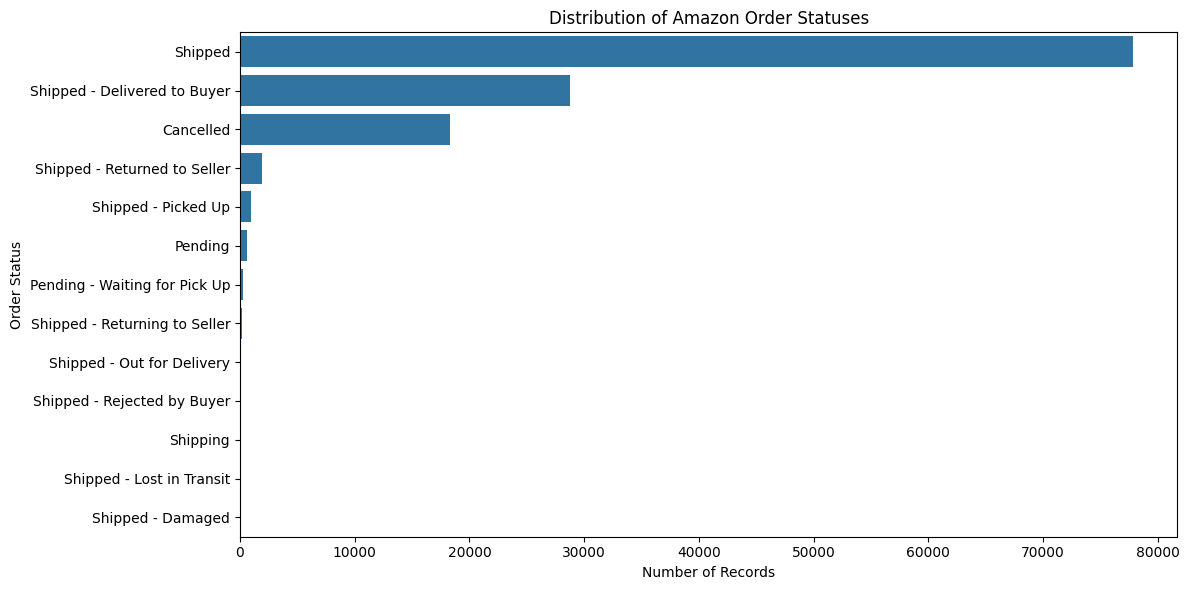

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count records for each order status
status_counts = df_clean["status"].value_counts()

# Create the chart
plt.figure(figsize=(12, 6))
sns.barplot(
    x=status_counts.values,
    y=status_counts.index
)

plt.title("Distribution of Amazon Order Statuses")
plt.xlabel("Number of Records")
plt.ylabel("Order Status")
plt.tight_layout()

# Save the chart
plt.savefig(
    "../visualizations/order_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [32]:
# Analyze product category distribution
category_counts = df_clean["category"].value_counts()

print("Number of unique product categories:", df_clean["category"].nunique())

print("\nTop 10 product categories by record count:")
print(category_counts.head(10))

Number of unique product categories: 9

Top 10 product categories by record count:
category
Set              50284
kurta            49877
Western Dress    15500
Top              10622
Ethnic Dress      1159
Blouse             926
Bottom             440
Saree              164
Dupatta              3
Name: count, dtype: int64


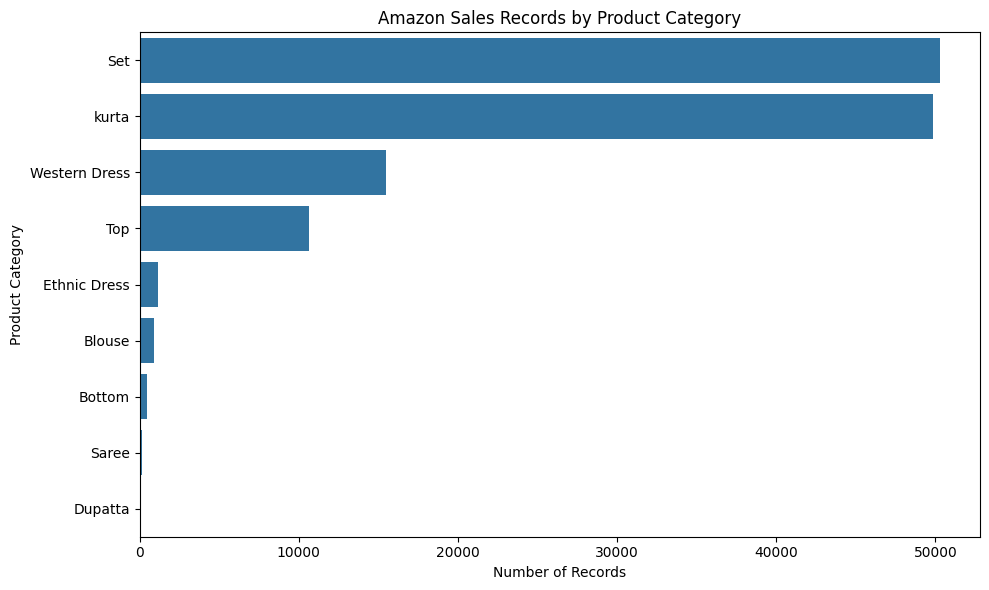

In [33]:

# Analyze product category distribution
category_counts = df_clean["category"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Amazon Sales Records by Product Category")
plt.xlabel("Number of Records")
plt.ylabel("Product Category")
plt.tight_layout()

# Save the visualization
plt.savefig(
    "../visualizations/product_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [34]:

# Calculate total recorded sales amount by product category
category_sales = (
    df_clean.groupby("category")["amount"]
    .sum(min_count=1)
    .sort_values(ascending=False)
)

print("Total recorded sales amount by category:")
print(category_sales.round(2))



Total recorded sales amount by category:
category
Set              39204124.03
kurta            21299546.70
Western Dress    11216072.69
Top               5347792.30
Ethnic Dress       791217.66
Blouse             458408.18
Bottom             150667.98
Saree              123933.76
Dupatta               915.00
Name: amount, dtype: float64


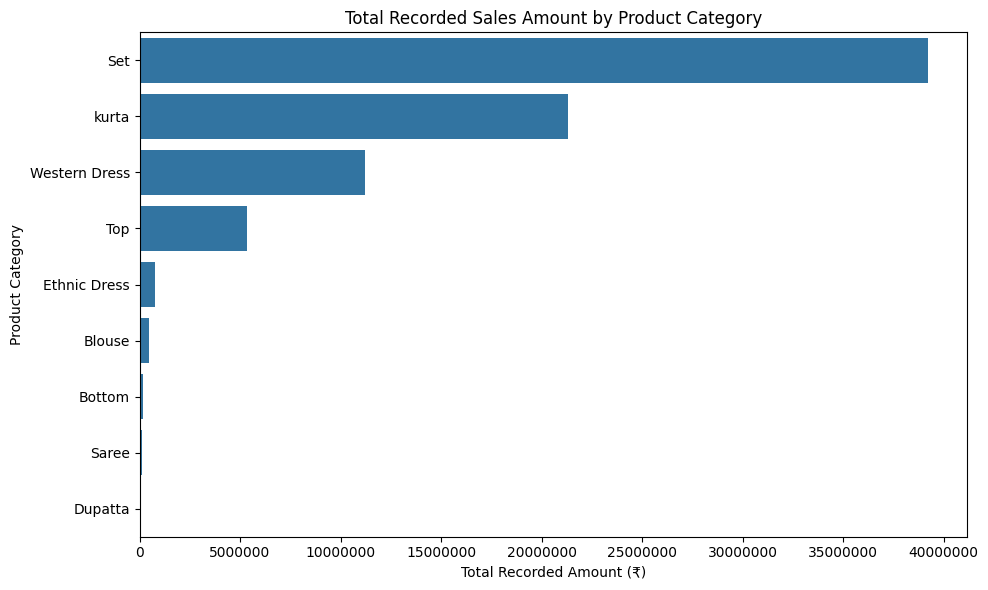

In [35]:

# Plot total recorded sales amount by category
plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index
)

plt.title("Total Recorded Sales Amount by Product Category")
plt.xlabel("Total Recorded Amount (₹)")
plt.ylabel("Product Category")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()

# Save the chart
plt.savefig(
    "../visualizations/sales_amount_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [36]:

# Calculate daily recorded sales amount
daily_sales = (
    df_clean.groupby("date")["amount"]
    .sum(min_count=1)
    .sort_index()
)

print("First 10 days of recorded sales:")
print(daily_sales.head(10))

print("\nDate range:", df_clean["date"].min(), "to", df_clean["date"].max())

print("\nNumber of dates:", daily_sales.index.nunique())



First 10 days of recorded sales:
date
2022-03-31     101683.85
2022-04-01     865478.60
2022-04-02     913101.53
2022-04-03    1011763.38
2022-04-04     882059.17
2022-04-05     950544.05
2022-04-06     886985.26
2022-04-07     909899.35
2022-04-08    1018617.61
2022-04-09     972076.48
Name: amount, dtype: float64

Date range: 2022-03-31 00:00:00 to 2022-06-29 00:00:00

Number of dates: 91


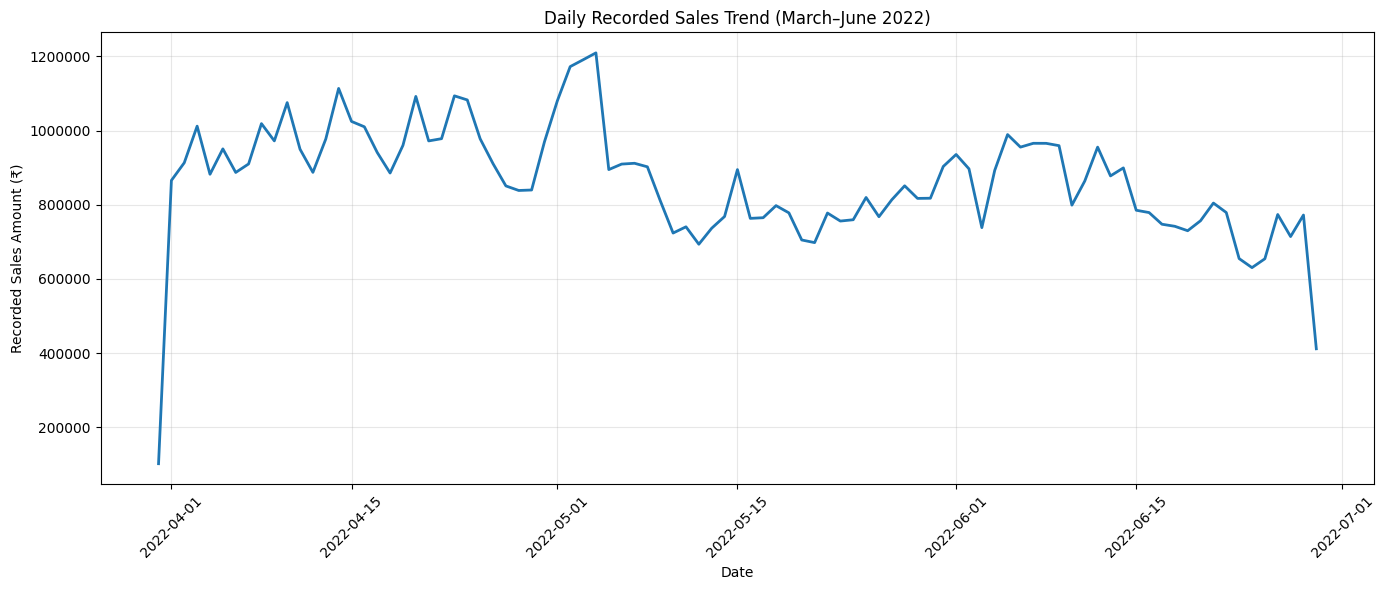

In [37]:

# Plot daily recorded sales amount
plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    linewidth=2
)

plt.title("Daily Recorded Sales Trend (March–June 2022)")
plt.xlabel("Date")
plt.ylabel("Recorded Sales Amount (₹)")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the chart
plt.savefig(
    "../visualizations/daily_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [38]:
id="1p8x6b"
# Calculate overall recorded sales statistics
total_sales = df_clean["amount"].sum()
average_amount = df_clean["amount"].mean()
median_amount = df_clean["amount"].median()
total_records = len(df_clean)
records_with_amount = df_clean["amount"].notna().sum()
missing_amounts = df_clean["amount"].isna().sum()

print("OVERALL SALES SUMMARY")
print("-" * 35)
print(f"Total recorded sales amount: ₹{total_sales:,.2f}")
print(f"Average amount per record: ₹{average_amount:,.2f}")
print(f"Median amount per record: ₹{median_amount:,.2f}")
print(f"Total records: {total_records:,}")
print(f"Records with an amount: {records_with_amount:,}")
print(f"Records with a missing amount: {missing_amounts:,}")



OVERALL SALES SUMMARY
-----------------------------------
Total recorded sales amount: ₹78,592,678.30
Average amount per record: ₹648.56
Median amount per record: ₹605.00
Total records: 128,975
Records with an amount: 121,180
Records with a missing amount: 7,795


In [39]:

# Calculate monthly recorded sales amount
monthly_sales = (
    df_clean.set_index("date")["amount"]
    .resample("ME")
    .sum(min_count=1)
)

print("Monthly recorded sales amount:")
print(monthly_sales.round(2))



Monthly recorded sales amount:
date
2022-03-31      101683.85
2022-04-30    28838708.32
2022-05-31    26226476.75
2022-06-30    23425809.38
Freq: ME, Name: amount, dtype: float64


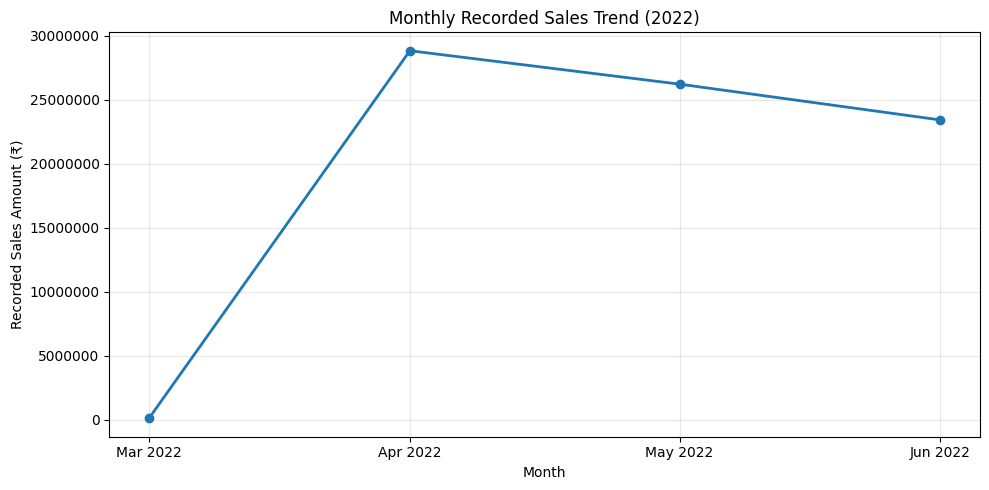

In [40]:

# Plot monthly recorded sales amount
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Recorded Sales Trend (2022)")
plt.xlabel("Month")
plt.ylabel("Recorded Sales Amount (₹)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(monthly_sales.index, ["Mar 2022", "Apr 2022", "May 2022", "Jun 2022"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the visualization
plt.savefig(
    "../visualizations/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [41]:

# Analyze order quantities
print("ORDER QUANTITY ANALYSIS")
print("-" * 35)

print("\nQuantity statistics:")
print(df_clean["qty"].describe())

print("\nQuantity distribution:")
print(df_clean["qty"].value_counts().sort_index())

print("\nRecords with zero quantity:", (df_clean["qty"] == 0).sum())
print("Records with quantity greater than 1:", (df_clean["qty"] > 1).sum())



ORDER QUANTITY ANALYSIS
-----------------------------------

Quantity statistics:
count    128975.000000
mean          0.904431
std           0.313354
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          15.000000
Name: qty, dtype: float64

Quantity distribution:
qty
0      12807
1     115780
2        341
3         32
4          9
5          2
8          1
9          1
13         1
15         1
Name: count, dtype: int64

Records with zero quantity: 12807
Records with quantity greater than 1: 388


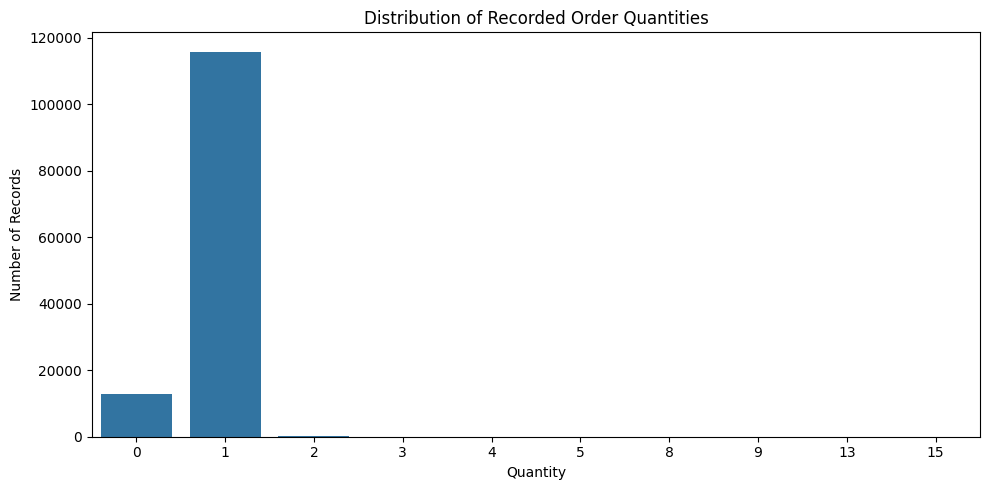

In [42]:

# Plot quantity distribution
quantity_counts = df_clean["qty"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=quantity_counts.index,
    y=quantity_counts.values
)

plt.title("Distribution of Recorded Order Quantities")
plt.xlabel("Quantity")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig(
    "../visualizations/quantity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [43]:

# Analyze quantity against order status
quantity_status = pd.crosstab(
    df_clean["status"],
    df_clean["qty"]
)

print("Quantity distribution by order status:")
print(quantity_status)

print("\nZero-quantity records by status:")
print(
    df_clean.loc[df_clean["qty"] == 0, "status"]
    .value_counts()
)



Quantity distribution by order status:
qty                               0      1    2   3   4   5   8   9   13  15
status                                                                      
Cancelled                      12701   5605   26   0   0   0   0   0   0   0
Pending                            2    655    1   0   0   0   0   0   0   0
Pending - Waiting for Pick Up      0    279    2   0   0   0   0   0   0   0
Shipped                           93  77477  208  17   5   0   1   1   1   1
Shipped - Damaged                  0      1    0   0   0   0   0   0   0   0
Shipped - Delivered to Buyer       8  28657   90   9   3   2   0   0   0   0
Shipped - Lost in Transit          0      5    0   0   0   0   0   0   0   0
Shipped - Out for Delivery         0     35    0   0   0   0   0   0   0   0
Shipped - Picked Up                0    969    4   0   0   0   0   0   0   0
Shipped - Rejected by Buyer        0     11    0   0   0   0   0   0   0   0
Shipped - Returned to Seller       3 

In [44]:

# Analyze recorded sales amounts by order status
status_sales = (
    df_clean.groupby("status")
    .agg(
        record_count=("status", "size"),
        records_with_amount=("amount", "count"),
        total_recorded_amount=("amount", "sum"),
        average_recorded_amount=("amount", "mean")
    )
    .sort_values("total_recorded_amount", ascending=False)
)

print("Recorded sales amount by order status:")
print(status_sales.round(2))



Recorded sales amount by order status:
                               record_count  records_with_amount  \
status                                                             
Shipped                               77804                77596   
Shipped - Delivered to Buyer          28769                28761   
Cancelled                             18332                10766   
Shipped - Returned to Seller           1953                 1950   
Shipped - Picked Up                     973                  973   
Pending                                 658                  656   
Pending - Waiting for Pick Up           281                  281   
Shipped - Returning to Seller           145                  145   
Shipped - Out for Delivery               35                   35   
Shipped - Rejected by Buyer              11                   11   
Shipped - Lost in Transit                 5                    5   
Shipped - Damaged                         1                    1   
Shipping 

In [45]:

# Final data quality check
print("FINAL DATA QUALITY CHECK")
print("-" * 35)

print("Dataset shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("\nRemaining missing values:")
print(
    df_clean.isnull()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

print("\nData types:")
print(df_clean.dtypes)



FINAL DATA QUALITY CHECK
-----------------------------------
Dataset shape: (128975, 23)
Duplicate rows: 0

Remaining missing values:
currency            7795
amount              7795
ship_city             33
ship_state            33
ship_postal_code      33
ship_country          33
dtype: int64

Data types:
index                          int64
order_id                      object
date                  datetime64[ns]
status                        object
fulfilment                    object
sales_channel                 object
ship_service_level            object
style                         object
sku                           object
category                      object
size                          object
asin                          object
courier_status                object
qty                            int64
currency                      object
amount                       float64
ship_city                     object
ship_state                    object
ship_postal_code        

In [46]:

# Export the cleaned dataset
df_clean.to_csv(
    "../data/Amazon_Sale_Report_Cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])



Cleaned dataset exported successfully!
Rows: 128975
Columns: 23
